![The blog’s ninja owl examining a probability orb](https://howtolearnmachinelearning.com/wp-content/uploads/2026/11/probability-calibration-anime-owl.png)

# Probability calibration in Python
**Hey friends!** Imagine a forecast gives 80% odds of rain and you wake up to sunshine. Was the forecast bad? One sunny day can happen. The interesting question is how often it rains across *many* days given similar forecasts.

In this lab you’ll ask the same question of a classifier, adjust its probabilities, and see whether the adjustment helps on fresh cases. Start at the top and run each cell with Shift+Enter. You’ll generate all the data locally. Allow about 15 minutes.

[Read the companion article](https://howtolearnmachinelearning.com/articles/probability-calibration-python/)

**Your challenge:** Choose the forecast for a review team. When you reach the challenge, enter your choices in the cell marked **Your attempt**, run it and use the feedback to try again. The final section contains a worked answer.

## 1. Audit ten forecasts by hand
Ten cases each received a probability of 0.8. How many positives would you expect? Run the cell, then change one outcome from 0 to 1. Watch which number moves.

In [ ]:
import numpy as np

outcomes = np.array([1, 1, 0, 1, 0, 1, 1, 0, 1, 0])
print(f"Expected positives: {0.8 * len(outcomes):.1f}")
print(f"Observed positives: {outcomes.sum()} of {len(outcomes)}")
print(f"Observed fraction: {outcomes.mean():.0%}")

In the original sample we saw six positives. The predicted fraction exceeded the observed fraction by 20 percentage points. With only ten observations, ordinary sampling variation could explain a gap this size. Let’s repeat the audit with more data.

## 2. Give each dataset one job
We’ll train a classifier on 6,000 cases, fit its probability adjustment on another 3,000, and evaluate both versions on the last 3,000. The random split suits these synthetic independent rows. For repeated customers or time series, split by customer or time as appropriate.

This lab uses scikit-learn 1.6+ for `FrozenEstimator`. If that import fails in Colab, run `%pip install -U "scikit-learn>=1.6"` in a separate cell, restart the session, then run from the top.

In [ ]:
import matplotlib.pyplot as plt
import sklearn
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.datasets import make_classification
from sklearn.frozen import FrozenEstimator
from sklearn.metrics import brier_score_loss, log_loss, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB

X, y = make_classification(n_samples=12000, n_features=12, n_informative=4,
                           n_redundant=6, weights=[0.8, 0.2], flip_y=0.02,
                           class_sep=1.0, random_state=42)
X_train, X_rest, y_train, y_rest = train_test_split(
    X, y, test_size=0.5, stratify=y, random_state=42)
X_cal, X_test, y_cal, y_test = train_test_split(
    X_rest, y_rest, test_size=0.5, stratify=y_rest, random_state=42)
for label, target in [('Training', y_train), ('Calibration', y_cal), ('Test', y_test)]:
    print(f'{label:<12} {len(target):,} cases | positive rate {target.mean():.1%}')
print('scikit-learn', sklearn.__version__)

## 3. Ask the classifier what it believes
Gaussian naive Bayes treats features as conditionally independent given the class. We deliberately included redundant features. Overlapping evidence can make its predictions too extreme. Let’s inspect six calibration cases before changing anything.

In [ ]:
base = GaussianNB().fit(X_train, y_train)
positive_column = list(base.classes_).index(1)
raw_cal = base.predict_proba(X_cal)[:, positive_column]
print("Raw probability   Outcome")
for probability, outcome in zip(raw_cal[:6], y_cal[:6]):
    print(f"{probability:>12.1%}   {outcome:>7}")

## 4. Fit the adjustment
A sigmoid calibrator learns a smooth mapping from the original scores to probabilities. Freezing the trained classifier keeps its fitted parameters fixed while the mapping learns from the calibration labels.

**Predict before running.** If two cases change from 0.95 and 0.80 to 0.56 and 0.43, which case still ranks higher?

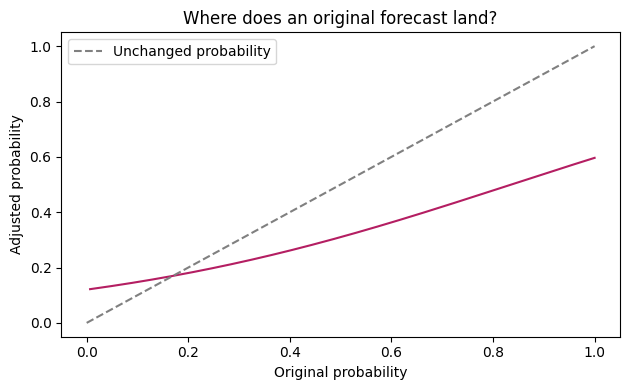

In [ ]:
calibrated = CalibratedClassifierCV(FrozenEstimator(base), method="sigmoid")
calibrated.fit(X_cal, y_cal)
predictions = {
    "Raw": base.predict_proba(X_test)[:, positive_column],
    "Sigmoid": calibrated.predict_proba(X_test)[:, list(calibrated.classes_).index(1)]
}
order = np.argsort(predictions["Raw"])
plt.figure(figsize=(6.4, 4))
plt.plot(predictions["Raw"][order], predictions["Sigmoid"][order], color="#b41e62")
plt.plot([0, 1], [0, 1], "--", color="gray", label="Unchanged probability")
plt.xlabel("Original probability")
plt.ylabel("Adjusted probability")
plt.title("Where does an original forecast land?")
plt.legend()
plt.tight_layout()
plt.show()

Follow the line from left to right. An increasing mapping preserves order. Where the line falls below the diagonal, the adjusted probability is smaller than the original one.

## 5. Check the 80% claim
Pick a probability band and inspect the cases that land inside it. Compare the **mean prediction** with the **fraction actually positive**. The two models can put different cases in the same band. An empty band tells you the model issued no predictions there.

In [ ]:
LOW, HIGH = 0.75, 0.85   # Also try 0.15, 0.25
assert 0 <= LOW < HIGH <= 1
for name, probabilities in predictions.items():
    upper = probabilities <= HIGH if HIGH == 1 else probabilities < HIGH
    mask = (probabilities >= LOW) & upper
    if mask.any():
        print(f"{name}: {mask.sum()} cases | mean forecast {probabilities[mask].mean():.1%}"
              f" | actually positive {y_test[mask].mean():.1%}")
    else:
        print(f"{name}: no forecasts in this band")

## 6. Zoom out across the whole probability range
The reliability diagram repeats that calculation for each occupied bin. A point below the diagonal means the model predicted the positive class more often than it occurred in that bin. The histogram tells you how much evidence each part of the curve has.

**Mini-challenge.** Run with 5 bins and again with 20. Which estimate would you trust more, a point based on 5 cases or one based on 500?

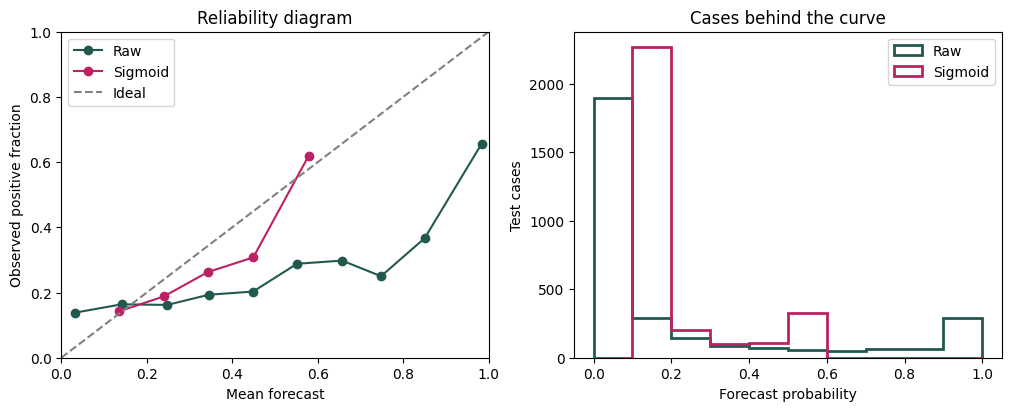

In [ ]:
N_BINS = 10
assert isinstance(N_BINS, int) and 2 <= N_BINS <= 50
edges = np.linspace(0, 1, N_BINS + 1)
fig, (curve, counts) = plt.subplots(1, 2, figsize=(10, 4), layout="constrained")
for (name, probabilities), color in zip(predictions.items(), ["#22594f", "#bc2164"]):
    observed, forecast = calibration_curve(y_test, probabilities, n_bins=N_BINS,
                                            strategy="uniform")
    curve.plot(forecast, observed, "o-", color=color, label=name)
    counts.hist(probabilities, bins=edges, histtype="step", linewidth=2,
                color=color, label=name)
curve.plot([0, 1], [0, 1], "--", color="gray", label="Ideal")
curve.set(xlabel="Mean forecast", ylabel="Observed positive fraction",
          title="Reliability diagram", xlim=(0, 1), ylim=(0, 1))
counts.set(xlabel="Forecast probability", ylabel="Test cases", title="Cases behind the curve")
for ax in (curve, counts):
    ax.legend()
plt.show()

## 7. Score the forecasts on the same test cases
**Brier score** averages squared probability errors. **Log loss** penalizes confident wrong predictions particularly strongly. Lower values are better for both. **ROC AUC** measures ranking, with higher values indicating better separation. Include a simple reference that predicts the training positive rate for everyone.

**Make a prediction.** Which metric should stay the same if the adjustment strictly preserves ranking?

## Your challenge · Choose the forecast for a review team
A team wants the forecast with the smallest Brier score among those that also beat the **training base-rate forecast** on log loss. Before opening the test scorecard, pick Raw, Sigmoid, or Base rate. Predict the direction of the ROC AUC change from Raw to Sigmoid. Use the scorecard to revise your decision and explain it using two numbers.

**Before trying it**, double-click this cell and finish the sentence: “I expect ___ because ___.”

In [ ]:
def check_forecast(forecast, ranking_prediction):
    choices = {**predictions, "Base rate": np.full(len(y_test), y_train.mean())}
    if forecast not in choices or ranking_prediction not in ("higher","same","lower"):
        print("Enter a forecast and your ranking prediction before revealing the scorecard.")
        return False
    losses = {name:(brier_score_loss(y_test,p), log_loss(y_test,p), roc_auc_score(y_test,p)) for name,p in choices.items()}
    print("Forecast        Brier   Log loss   ROC AUC")
    for name,(brier,loss,auc_value) in losses.items():
        print(f"{name:<11} {brier:8.4f} {loss:9.4f} {auc_value:9.4f}")
    eligible = [name for name in choices if losses[name][1] < losses["Base rate"][1]]
    winner = min(eligible, key=lambda name:losses[name][0])
    delta = round(losses["Sigmoid"][2],4) - round(losses["Raw"][2],4)
    direction = "higher" if delta > 0 else "lower" if delta < 0 else "same"
    if forecast != winner:
        print("Compare each log loss with the base-rate row before comparing Brier scores.")
    if ranking_prediction != direction:
        print("Compare the last column at four decimal places. Did the mapping reverse any ranks?")
    if forecast == winner and ranking_prediction == direction:
        print("Both checks passed. Which two numbers support your recommendation?")
        return True
    return False

**Your attempt.** Replace each `None` below with your choice. Rerun this cell after each change.

In [ ]:
forecast = None  # "Raw", "Sigmoid", or "Base rate"
ranking_prediction = None  # "higher", "same", or "lower" (to 4 decimal places)
mission_passed = check_forecast(forecast, ranking_prediction)

**Decision note.** Edit this cell after your experiment. “I chose ___ because I observed ___. One alternative I ruled out was ___ because ___.”

In [ ]:
if mission_passed:
    print("Use your scorecard above to write your recommendation.")
else:
    print("Complete the forecast challenge above to reveal your scorecard.")

### Check your answers
- The first case in the Step 4 puzzle still ranks higher. In the article’s experiment, ROC AUC stays at **0.7027** while Brier score falls from **0.1726 to 0.1422** and log loss falls from **0.6508 to 0.4548**. A reader who only checked ROC AUC would miss that improvement.
- The 500-case bin usually has less sampling noise, assuming comparable independent cases. Adding more bins can reveal detail while making sparsely populated regions harder to interpret.
- Brier score reflects several aspects of probability quality. Use the reliability diagram and bin counts to assess calibration directly. If you use these test results to choose a new calibration method, reserve fresh data for the next final evaluation.

**One last question, friends.** If your next batch of users comes from a different population, how would you know whether the adjustment still works? Once outcomes arrive, check the curve, counts and scores again on that population.

[Explore the Brier score](https://howtolearnmachinelearning.com/articles/brier-score/) · [Choose a decision threshold](https://howtolearnmachinelearning.com/articles/classification-threshold-tuning/) · [Get the free 90-Day Machine Learning Roadmap](https://how-to-learn-machine-learning.kit.com/7a25f667cb)

[scikit-learn probability calibration guide](https://scikit-learn.org/stable/modules/calibration.html)

## Worked answers
Sigmoid has log loss 0.4548 versus 0.5104 for the base rate. Its Brier score is 0.1422 versus 0.1726 for Raw. Both model rankings have ROC AUC 0.7027. These are results on one synthetic test set. A model selected after inspecting this scorecard needs a fresh evaluation before deployment.

In [ ]:
check_forecast("Sigmoid", "same")